# 03 · Basic analytics

Descriptive statistics on the cleaned comments (`data/comments_clean.csv`), with the raw table used where the question is about the raw data (for example the empty-comment count).

Results are shown **per creator**: Josh Pate has about three quarters of the comments, so pooled numbers would mostly describe his audience.

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_clean.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 29)

In [3]:
raw = pd.read_csv(config.DATA_DIR / "comments_raw.csv", keep_default_na=False)
log = pd.read_csv(config.DATA_DIR / "cleaning_log.csv")

overview = pd.Series({
    "raw comments": len(raw),
    "empty comments (raw)": int((raw["text_body"].str.strip() == "").sum()),
    "removed in cleaning": int(log["removed"].sum()),
    "clean comments": len(df),
    "videos": df["video_id"].nunique(),
    "unique commenters": df["author_channel_id"].nunique(),
    "top-level comments": int((~df["is_reply"]).sum()),
    "replies": int(df["is_reply"].sum()),
})
overview

raw comments            9561
empty comments (raw)       0
removed in cleaning      105
clean comments          9456
videos                    18
unique commenters       4852
top-level comments      4790
replies                 4666
dtype: int64

## 1. Comment counts by creator, period and video

In [4]:
counts = pd.crosstab([df["role"], df["creator_name"]], df["period"]).reindex(columns=PERIOD_ORDER, fill_value=0)
counts["total"] = counts.sum(axis=1)
counts

period                   before  announcement  after  total
role       creator_name                                    
primary    Crain & Cone     724           448    427   1599
           Josh Pate       2856           389   2439   5684
supplement Crain & Cone     434             0      0    434
           Josh Pate       1739             0      0   1739

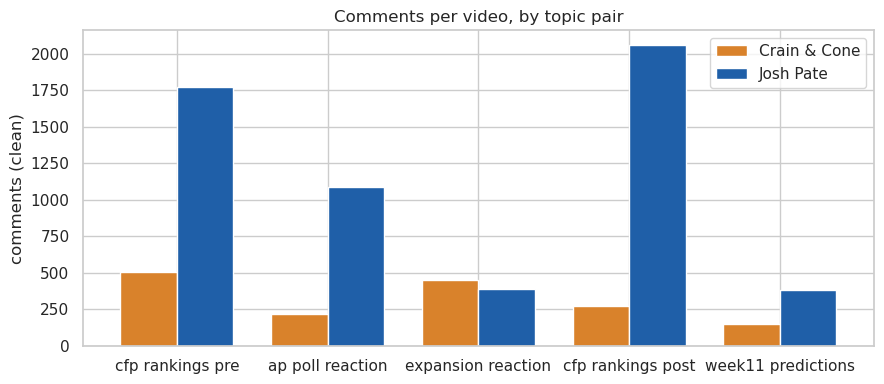

In [5]:
prim = df[df["role"] == "primary"]
pair_counts = prim.groupby(["topic_pair", "creator_name"]).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4))
pair_counts.plot.bar(ax=ax, color=[CREATOR_COLORS[c] for c in pair_counts.columns], width=0.75)
ax.set(xlabel="", ylabel="comments (clean)", title="Comments per video, by topic pair")
ax.set_xticklabels([t.split("_", 1)[1].replace("_", " ") for t in pair_counts.index], rotation=0)
ax.legend(title="")
save(fig, "03_comments_per_pair.png")

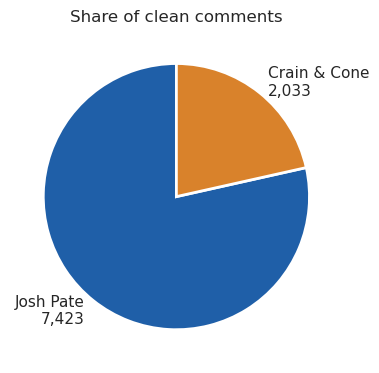

In [6]:
share = df["creator_name"].value_counts()
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(share, labels=[f"{k}\n{v:,}" for k, v in share.items()], colors=[CREATOR_COLORS[k] for k in share.index],
       startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
ax.set_title("Share of clean comments")
save(fig, "03_creator_share_pie.png")

## 2. Unique commenters

How concentrated is the conversation? And do the two audiences overlap?

In [7]:
per_commenter = df.groupby("author_channel_id").size()
print("comments per commenter:")
print(per_commenter.describe().round(2).to_string())
top10_share = per_commenter.sort_values(ascending=False).head(int(len(per_commenter) * 0.10)).sum() / len(df)
print(f"\nthe most active 10% of commenters wrote {top10_share:.0%} of comments")
print(f"commenters with only one comment: {(per_commenter == 1).mean():.0%}")

comments per commenter:
count    4852.00
mean        1.95
std         2.52
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        73.00

the most active 10% of commenters wrote 37% of comments
commenters with only one comment: 66%


In [8]:
by_creator = df.groupby("creator_name")["author_channel_id"].agg(comments="size", unique_commenters="nunique")
by_creator["comments_per_commenter"] = (by_creator["comments"] / by_creator["unique_commenters"]).round(2)

audiences = df.groupby("creator_name")["author_channel_id"].apply(set)
both = audiences["Josh Pate"] & audiences["Crain & Cone"]
print(f"commenters on both creators' videos: {len(both)} "
      f"({len(both) / df['author_channel_id'].nunique():.1%} of all commenters)")
by_creator

commenters on both creators' videos: 216 (4.5% of all commenters)


,comments,unique_commenters,comments_per_commenter
creator_name,,,
Crain & Cone,2033,1095,1.86
Josh Pate,7423,3973,1.87


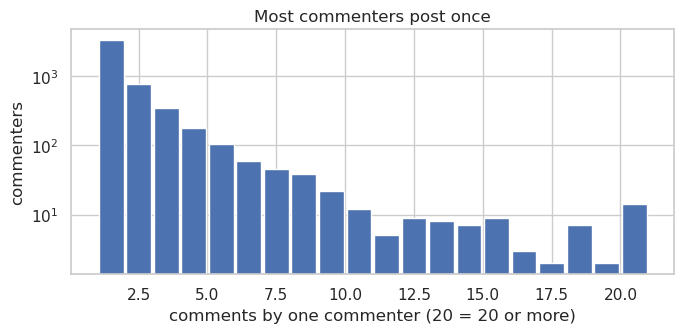

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(per_commenter.clip(upper=20), bins=range(1, 22), color="#4c72b0", rwidth=0.9)
ax.set(xlabel="comments by one commenter (20 = 20 or more)", ylabel="commenters", yscale="log",
       title="Most commenters post once")
save(fig, "03_comments_per_commenter.png")

## 3. Comment length

In [10]:
df["n_chars"] = df["text_body"].str.len()
df["n_words"] = df["text_body"].str.split().str.len()

df.groupby("creator_name")[["n_chars", "n_words"]].describe().round(1).T

creator_name   Crain & Cone  Josh Pate
n_chars count        2033.0     7423.0
        mean          148.9      155.0
        std           243.2      197.3
        min             1.0        1.0
        25%            43.0       49.0
        50%            91.0       97.0
        75%           172.0      186.0
        max          6660.0     5571.0
n_words count        2033.0     7423.0
        mean           28.3       29.3
        std            46.3       36.9
        min             1.0        1.0
        25%             9.0        9.0
        50%            17.0       19.0
        75%            33.0       35.0
        max          1295.0     1087.0

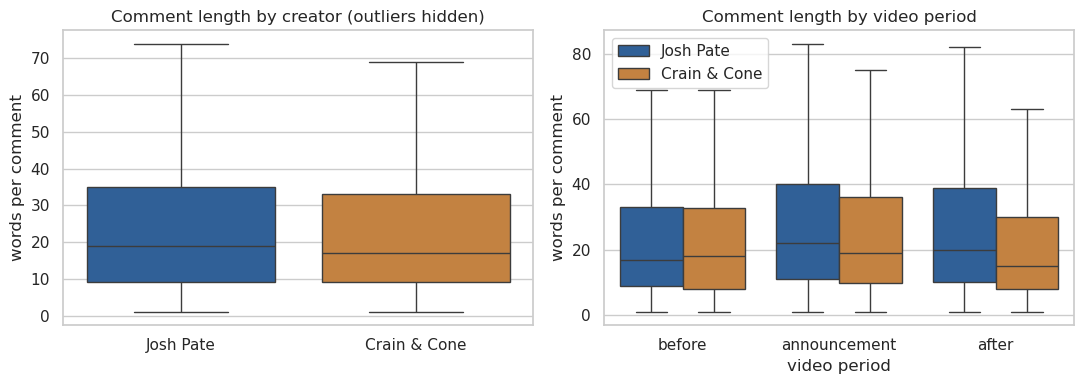

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="creator_name", y="n_words", hue="creator_name", palette=CREATOR_COLORS,
            showfliers=False, ax=axes[0], legend=False)
axes[0].set(xlabel="", ylabel="words per comment", title="Comment length by creator (outliers hidden)")
sns.boxplot(data=df, x="period", y="n_words", hue="creator_name", order=PERIOD_ORDER, palette=CREATOR_COLORS,
            showfliers=False, ax=axes[1])
axes[1].set(xlabel="video period", ylabel="words per comment", title="Comment length by video period")
axes[1].legend(title="")
save(fig, "03_length_boxplots.png")

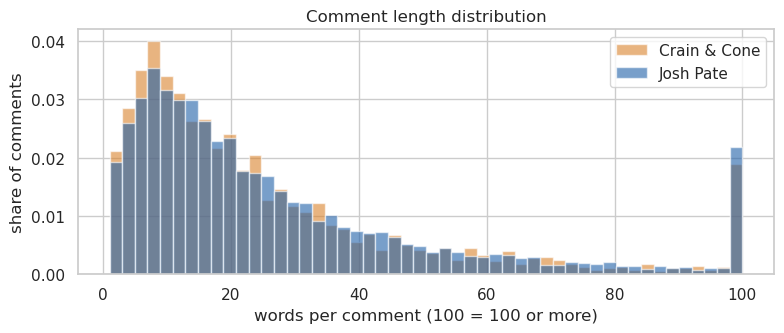

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, g in df.groupby("creator_name"):
    ax.hist(g["n_words"].clip(upper=100), bins=50, alpha=0.6, density=True, label=name, color=CREATOR_COLORS[name])
ax.set(xlabel="words per comment (100 = 100 or more)", ylabel="share of comments", title="Comment length distribution")
ax.legend()
save(fig, "03_length_hist.png")

In [13]:
print("replies vs top-level, median words:")
df.groupby(["creator_name", "is_reply"])["n_words"].median().unstack().rename(columns={False: "top-level", True: "reply"})

replies vs top-level, median words:


is_reply,top-level,reply
creator_name,,
Crain & Cone,19.0,15.0
Josh Pate,20.0,17.0


## 4. Replies and likes

In [14]:
reply_share = df.groupby(["creator_name", "period"])["is_reply"].mean().unstack().reindex(columns=PERIOD_ORDER)
print("share of comments that are replies:")
(reply_share * 100).round(1)

share of comments that are replies:


period,before,announcement,after
creator_name,,,
Crain & Cone,44.7,39.1,51.3
Josh Pate,50.2,39.8,53.0


In [15]:
print("likes per comment:")
print(df.groupby("creator_name")["like_count"].describe(percentiles=[.5, .9, .99]).round(1).to_string())
print("\nmost-liked comments:")
df.nlargest(10, "like_count")[["creator_name", "like_count", "video_title", "text_body"]]

likes per comment:
               count  mean   std  min  50%  90%   99%    max
creator_name                                                
Crain & Cone  2033.0   1.4   4.5  0.0  0.0  3.0  18.7   81.0
Josh Pate     7423.0   2.4  15.0  0.0  0.0  4.0  41.0  485.0

most-liked comments:


,creator_name,like_count,video_title,text_body
4274,Josh Pate,485,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,Alabama at 5 is insane.
7407,Josh Pate,463,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,Did the committee forget Alabama got walked by Tennessee 🧐
4332,Josh Pate,378,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,I’m a Bama homer. Bama at 5 is crazy.
1566,Josh Pate,300,CFP & National Championship Predictions...UPDATED - Josh Pate's College Football Show,Why is LSU still in? Where is their high quality win?
4583,Josh Pate,274,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,"Texas at #7 with losses to TWO UNRANKED team's, ahead of UCLA, ND etc. is crazy."
3165,Josh Pate,272,Why The 24-Team CFP Is A Massive Mistake - Josh Pate's College Football Show,I think they should expand the play off even further. Allow 75-100 teams in. You could divide the top 50 o...
7460,Josh Pate,264,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,One thing McElroy said about Tennessee: he thinks the committee is taking into account the fact that Tenne...
1595,Josh Pate,259,CFP & National Championship Predictions...UPDATED - Josh Pate's College Football Show,LSU has shown nothing to deserve this type of recognition
8041,Josh Pate,240,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,Head to head counts for everyone except Alabama...gotcha 👎
2489,Josh Pate,225,Georgia DESTROYS Ole Miss...FULL Reaction - Josh Pate's College Football Show,I was here when the thumbnail said UGA 41 Ole Miss 28


## 5. Comment timing (overview)

Detailed time series are in notebook 05; this is the overall shape.

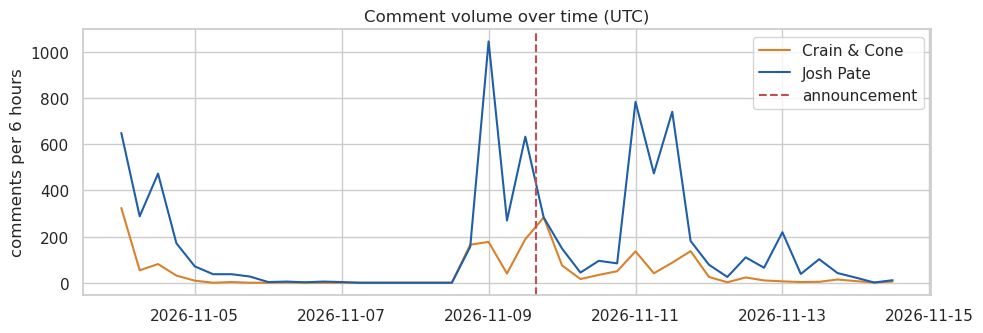

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.5))
hourly = df.set_index("published_utc").groupby("creator_name").resample("6h").size().unstack(0).fillna(0)
for name in hourly.columns:
    ax.plot(hourly.index, hourly[name], label=name, color=CREATOR_COLORS[name])
ax.axvline(config.ANNOUNCE_UTC, color="#c44e52", ls="--", label="announcement")
ax.set(ylabel="comments per 6 hours", title="Comment volume over time (UTC)")
ax.legend()
save(fig, "03_volume_over_time.png")

In [17]:
df.drop(columns=["creator_name"]).to_csv(config.DATA_DIR / "comments_clean.csv", index=False)
print("added n_chars / n_words to comments_clean.csv")

added n_chars / n_words to comments_clean.csv
